# Rank-k SVD Compression of Images and Neural-Network Weights — Full Experiments
Muhammad Zain Hassan · 26i-8015 · MSDS 1A · Mathematical and Statistical Foundations for Data Science, Fall 2026

**Research question:** how does the retained rank k change reconstruction error and classification accuracy when SVD is applied
(A) to the images and (B) to the first-layer weight matrix of a small trained network?

| Section | What it does |
|---|---|
| 1–3 | Data, SVD, Eckart–Young check |
| 4 | Part A: reconstruction and PCA-feature classifier |
| 5 | Pictures: reconstructions and top singular vectors |
| 6 | Part B: network trained to convergence, several seeds |
| 7 | Part B: plain SVD vs data-aware SVD vs frozen retraining |
| 8 | Why rank-k weights still work: weight error vs error on real inputs |
| 9 | Summary tables and plots |

Set `DATASET = "fashion"` for Fashion-MNIST (OpenML, 50k/10k/10k) or `"digits"` for UCI digits (60/20/20).
All numbers are validation numbers. The test set is held back and used once for the final paper.

In [1]:
DATASET = "digits"        # "fashion" or "digits"
SEED = 42
SEEDS = [42, 43, 44, 45, 46]  # network seeds for Part B
RETRAIN_EPOCHS = 2
import platform, time, copy, numpy as np, sklearn, matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
import warnings; warnings.filterwarnings("ignore")
print("python", platform.python_version(), "| numpy", np.__version__, "| sklearn", sklearn.__version__, "| matplotlib", matplotlib.__version__)

python 3.13.18 | numpy 2.5.3 | sklearn 1.9.1 | matplotlib 3.11.2


## 1. Load data and split (train / validation / test)

In [2]:
if DATASET == "fashion":
    from sklearn.datasets import fetch_openml
    X, y = fetch_openml("Fashion-MNIST", version=1, return_X_y=True, as_frame=False, parser="auto")
    X = X.astype(np.float64) / 255.0; y = y.astype(int)
    X_tr, y_tr = X[:50000], y[:50000]
    X_va, y_va = X[50000:60000], y[50000:60000]
    X_te, y_te = X[60000:], y[60000:]
    KS = [1, 2, 5, 10, 20, 50, 100, 200]; SIDE = 28; PIC_KS = [5, 20, 100]
else:
    from sklearn.datasets import load_digits
    d = load_digits(); X = d.data / 16.0; y = d.target
    X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.4, random_state=SEED, stratify=y)
    X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.5, random_state=SEED, stratify=y_tmp)
    KS = [1, 2, 5, 10, 20, 50]; SIDE = 8; PIC_KS = [2, 5, 20]
print("train", X_tr.shape, "| val", X_va.shape, "| test", X_te.shape, "(test not used)")

train (1078, 64) | val (359, 64) | test (360, 64) (test not used)


## 2. SVD of the centred training matrix
X_c = U Σ Vᵀ, rank-k reconstruction X_k = U_k Σ_k V_kᵀ. The mean and the SVD are fitted on training data only.

In [3]:
mu = X_tr.mean(axis=0)
U, S, Vt = np.linalg.svd(X_tr - mu, full_matrices=False)
energy = np.cumsum(S**2) / np.sum(S**2)
print("ranks for 90% image energy:", int(np.searchsorted(energy, 0.90) + 1), "of", len(S))

ranks for 90% image energy: 21 of 64


## 3. Eckart–Young check
The theorem says ‖X_c − X_k‖²_F = Σ_{i>k} σᵢ². Both sides are computed independently.

In [4]:
for k in [5, 10, 20]:
    Xk = (U[:, :k] * S[:k]) @ Vt[:k]
    lhs = np.sum((X_tr - mu - Xk)**2); rhs = np.sum(S[k:]**2)
    print(f"k={k:3d}  ||Xc-Xk||^2 = {lhs:.6f}   sum_(i>k) s_i^2 = {rhs:.6f}   rel. diff = {abs(lhs-rhs)/rhs:.1e}")

k=  5  ||Xc-Xk||^2 = 2289.278189   sum_(i>k) s_i^2 = 2289.278189   rel. diff = 4.0e-16
k= 10  ||Xc-Xk||^2 = 1320.098661   sum_(i>k) s_i^2 = 1320.098661   rel. diff = 1.7e-16
k= 20  ||Xc-Xk||^2 = 526.927624   sum_(i>k) s_i^2 = 526.927624   rel. diff = 2.2e-16


## 4. Part A — reconstruction error and logistic regression on k PCA features (validation)

In [5]:
def recon_mse(k, Xs):
    if k == 0: return np.mean((mu - Xs)**2)
    Z = (Xs - mu) @ Vt[:k].T
    return np.mean((Z @ Vt[:k] + mu - Xs)**2)
def clf_acc(k):
    clf = LogisticRegression(max_iter=2000, random_state=SEED)
    clf.fit((X_tr - mu) @ Vt[:k].T, y_tr)
    return clf.score((X_va - mu) @ Vt[:k].T, y_va)
A = {k: (energy[k-1], recon_mse(k, X_va), clf_acc(k)) for k in KS}
A0_mse = recon_mse(0, X_va)
A_full = LogisticRegression(max_iter=2000, random_state=SEED).fit(X_tr, y_tr).score(X_va, y_va)
print("mean-image (k=0) MSE: %.4f | full-pixel accuracy: %.3f" % (A0_mse, A_full))

mean-image (k=0) MSE: 0.0728 | full-pixel accuracy: 0.958


## 5. Pictures — validation images rebuilt at several k, and the top singular vectors (eigen-images)

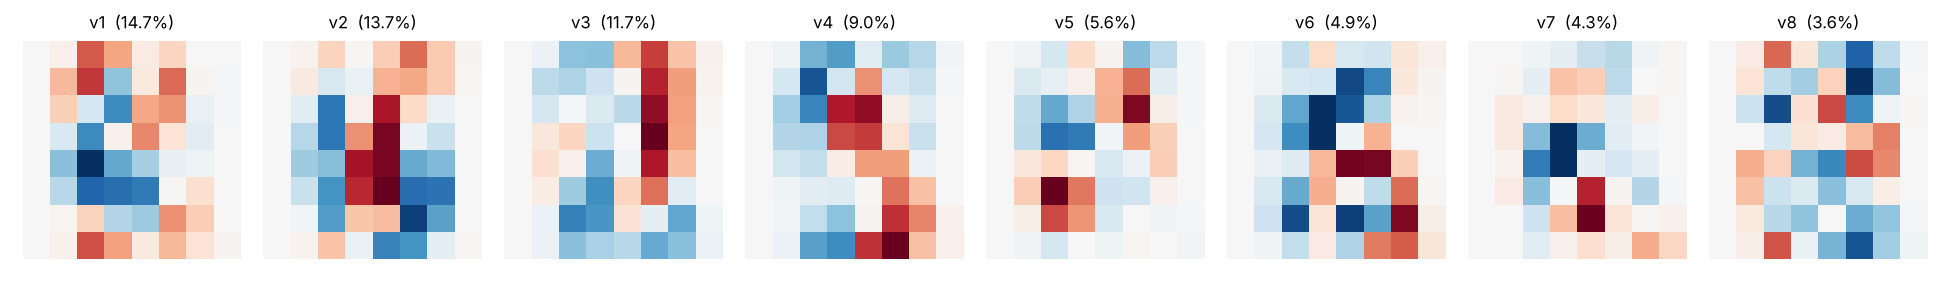

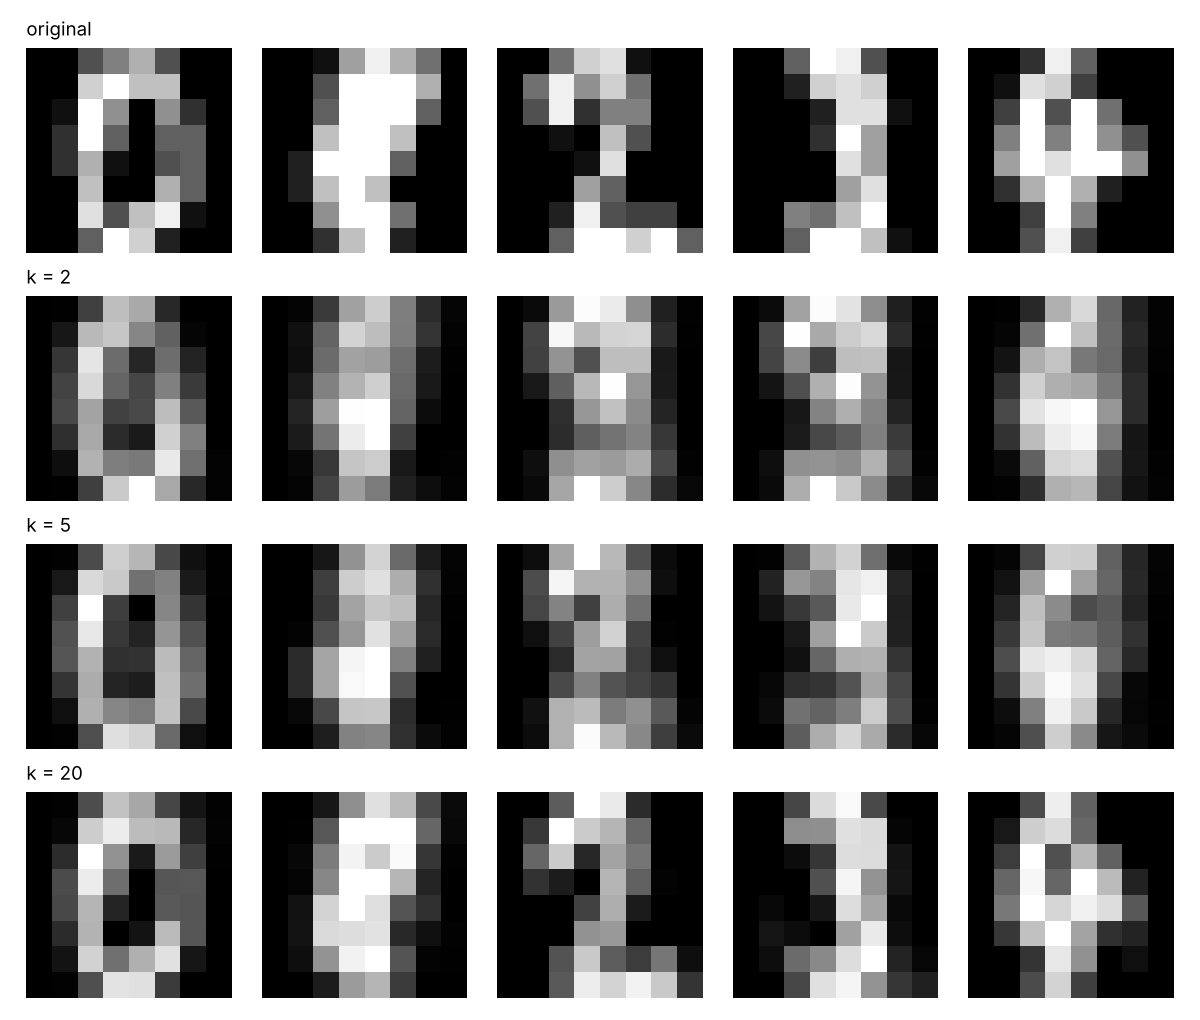

In [6]:
idx = [int(np.where(y_va == c)[0][0]) for c in range(5)]
rows = [("original", X_va[idx])] + [(f"k = {k}", ((X_va[idx] - mu) @ Vt[:k].T) @ Vt[:k] + mu) for k in PIC_KS]
fig, ax = plt.subplots(len(rows), len(idx), figsize=(1.6*len(idx), 1.7*len(rows)))
for r, (name, imgs) in enumerate(rows):
    for c in range(len(idx)):
        ax[r, c].imshow(np.clip(imgs[c], 0, 1).reshape(SIDE, SIDE), cmap="gray"); ax[r, c].axis("off")
    ax[r, 0].set_title(name, loc="left", fontsize=9)
plt.tight_layout(); plt.savefig(f"reconstructions_{DATASET}.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 8, figsize=(13, 2))
for i in range(8):
    v = Vt[i].reshape(SIDE, SIDE); m = np.abs(v).max()
    ax[i].imshow(v, cmap="RdBu_r", vmin=-m, vmax=m); ax[i].axis("off")
    ax[i].set_title(f"v{i+1}  ({S[i]**2/np.sum(S**2):.1%})", fontsize=8)
plt.tight_layout(); plt.savefig(f"eigen_images_{DATASET}.png", dpi=150); plt.show()

## 6. Part B — train the network to convergence (several seeds)
MLPClassifier, one hidden layer of 256 units, Adam. Training stops when the internal validation score (10% of the
training set) stops improving for 10 epochs (`early_stopping=True`), capped at 200 epochs.

In [7]:
nets = {}
for s in SEEDS:
    t0 = time.time()
    nets[s] = MLPClassifier(hidden_layer_sizes=(256,), max_iter=200, early_stopping=True, random_state=s).fit(X_tr, y_tr)
    print(f"seed {s}: {nets[s].n_iter_} epochs, val acc {nets[s].score(X_va, y_va):.3f}, {time.time()-t0:.1f} s")
W = nets[SEED].coefs_[0]; m, n = W.shape
Sw = np.linalg.svd(W, compute_uv=False); ew = np.cumsum(Sw**2) / np.sum(Sw**2)
print("W shape", W.shape, "| ranks for 90% weight energy (seed 42):", int(np.searchsorted(ew, 0.90) + 1), "of", len(Sw))

seed 42: 37 epochs, val acc 0.950, 0.2 s
seed 43: 33 epochs, val acc 0.944, 0.2 s
seed 44: 43 epochs, val acc 0.947, 0.2 s
seed 45: 25 epochs, val acc 0.928, 0.1 s
seed 46: 40 epochs, val acc 0.944, 0.2 s
W shape (64, 256) | ranks for 90% weight energy (seed 42): 44 of 64


## 7. Part B — three ways to get a rank-k first layer
Everything except W stays as trained. All three store k(m+n) numbers instead of mn.

1. **Plain SVD:** W_k = U_k Σ_k V_kᵀ of W. Best rank-k fit to W itself (Eckart–Young).
2. **Data-aware SVD:** best rank-k fit to the layer's *output on training data*: minimise ‖X W − X W'‖_F.
   With XW = P Λ Qᵀ, the solution is W' = W Q_k Q_kᵀ. Same storage, but the error is measured where the data lives
   (the idea behind SVD-LLM).
2c. **Centred data-aware SVD:** the same fit on centred inputs, (X − μ)W. The part of the output caused by the mean image,
   μ(W − W'), is moved into the bias, so the average output stays exact and the k directions are spent on what differs
   between images. No extra storage: the bias vector already exists.
3. **Plain SVD + frozen retraining:** keep the rank-k first layer fixed and retrain the output layer and biases for
   a few epochs on training data. W is reset to W_k after every mini-batch, so the first layer stays exactly rank k.

In [8]:
def acc_with(net, Wnew):
    old = net.coefs_[0]; net.coefs_[0] = Wnew
    a = net.score(X_va, y_va); net.coefs_[0] = old
    return a
def plain_svd(W, k):
    Uw, Sw_, Vtw = np.linalg.svd(W, full_matrices=False)
    return (Uw[:, :k] * Sw_[:k]) @ Vtw[:k]
def data_aware(W, k):
    _, _, Qt = np.linalg.svd(X_tr @ W, full_matrices=False)
    Qk = Qt[:k].T
    return W @ Qk @ Qk.T
def data_aware_centred(W, b, k):
    _, _, Qt = np.linalg.svd((X_tr - mu) @ W, full_matrices=False)
    Qk = Qt[:k].T; Wk = W @ Qk @ Qk.T
    return Wk, b + mu @ (W - Wk)
def acc_with_bias(net, Wnew, bnew):
    oldW, oldb = net.coefs_[0], net.intercepts_[0]
    net.coefs_[0], net.intercepts_[0] = Wnew, bnew
    a = net.score(X_va, y_va); net.coefs_[0], net.intercepts_[0] = oldW, oldb
    return a
def frozen_retrain(net, Wk, seed):
    net2 = copy.deepcopy(net); net2.coefs_[0] = Wk.copy(); net2.early_stopping = False; net2.best_loss_ = np.inf
    rng = np.random.default_rng(seed)
    for _ in range(RETRAIN_EPOCHS):
        for b in np.array_split(rng.permutation(len(X_tr)), max(1, len(X_tr) // 200)):
            net2.partial_fit(X_tr[b], y_tr[b]); net2.coefs_[0] = Wk.copy()
    return net2.score(X_va, y_va)
R = {key: {k: [] for k in KS} for key in ["plain", "data", "datac", "retrain"]}
full_acc, werr, oerr, oerr_da = [], {k: [] for k in KS}, {k: [] for k in KS}, {k: [] for k in KS}
t0 = time.time()
for s, net in nets.items():
    Ws = net.coefs_[0]; full_acc.append(net.score(X_va, y_va))
    for k in KS:
        Wp, Wd = plain_svd(Ws, k), data_aware(Ws, k)
        R["plain"][k].append(acc_with(net, Wp)); R["data"][k].append(acc_with(net, Wd))
        Wc, bc = data_aware_centred(Ws, net.intercepts_[0], k)
        R["datac"][k].append(acc_with_bias(net, Wc, bc))
        R["retrain"][k].append(frozen_retrain(net, Wp, s))
        werr[k].append(np.linalg.norm(Ws - Wp) / np.linalg.norm(Ws))
        oerr[k].append(np.linalg.norm(X_va @ (Ws - Wp)) / np.linalg.norm(X_va @ Ws))
        oerr_da[k].append(np.linalg.norm(X_va @ (Ws - Wd)) / np.linalg.norm(X_va @ Ws))
print(f"done in {time.time()-t0:.1f} s")

done in 2.8 s


## 8. Why does a damaged weight matrix still work?
Compare the relative error in W itself, ‖W − W_k‖_F / ‖W‖_F, with the relative error the layer makes on real validation
images, ‖X(W − W_k)‖_F / ‖XW‖_F. If the second is much smaller, the discarded weight directions are ones the images barely
excite. The check below measures this directly: the share of the images' energy (uncentred, as the network sees them) that
falls in the top-k left singular directions of W, against the share of W's own energy in those directions.

In [9]:
Uw = np.linalg.svd(W, full_matrices=False)[0]
xe = np.sum((X_va @ Uw)**2, axis=0) / np.sum(X_va**2)   # image energy along each left singular direction of W
print(f"{'k':>5} {'W energy kept':>14} {'image energy in kept dirs':>26}")
for k in KS:
    print(f"{k:>5} {ew[k-1]:14.3f} {np.sum(xe[:k]):26.3f}")
print("(image energy along all directions of W sums to %.3f; W is %dx%d)" % (np.sum(xe), m, n))

    k  W energy kept  image energy in kept dirs
    1          0.082                      0.032
    2          0.147                      0.055
    5          0.302                      0.114
   10          0.463                      0.728
   20          0.646                      0.780
   50          0.946                      0.940
(image energy along all directions of W sums to 1.000; W is 64x256)


## 9. Summary tables (mean ± sd over seeds) and plots

In [10]:
ms = lambda v: f"{np.mean(v):.3f} ± {np.std(v):.3f}"
print("Part A (single deterministic fit)")
print(f"{'k':>5} {'expl.var':>9} {'recon MSE':>10} {'A acc':>7}")
print(f"{0:>5} {0.0:9.3f} {A0_mse:10.4f} {'—':>7}")
for k in KS: print(f"{k:>5} {A[k][0]:9.3f} {A[k][1]:10.4f} {A[k][2]:7.3f}")
print(f"{'full':>5} {1.0:9.3f} {0.0:10.4f} {A_full:7.3f}")
print()
print(f"Part B over {len(SEEDS)} seeds; full-rank network: {ms(full_acc)}")
print(f"{'k':>5} {'stored':>7} {'plain SVD':>15} {'data-aware SVD':>15} {'centred DA SVD':>15} {'plain + retrain':>16} {'W rel.err':>10} {'output rel.err':>15} {'output err (DA)':>16}")
for k in KS:
    print(f"{k:>5} {k*(m+n)/(m*n):7.2f} {ms(R['plain'][k]):>15} {ms(R['data'][k]):>15} {ms(R['datac'][k]):>15} {ms(R['retrain'][k]):>16} "
          f"{np.mean(werr[k]):10.2f} {np.mean(oerr[k]):15.2f} {np.mean(oerr_da[k]):16.2f}")

Part A (single deterministic fit)
    k  expl.var  recon MSE   A acc
    0     0.000     0.0728       —
    1     0.147     0.0619   0.357
    2     0.284     0.0518   0.599
    5     0.548     0.0334   0.850
   10     0.739     0.0195   0.936
   20     0.896     0.0081   0.953
   50     1.000     0.0001   0.958
 full     1.000     0.0000   0.958

Part B over 5 seeds; full-rank network: 0.943 ± 0.008
    k  stored       plain SVD  data-aware SVD  centred DA SVD  plain + retrain  W rel.err  output rel.err  output err (DA)
    1    0.02   0.212 ± 0.007   0.097 ± 0.000   0.285 ± 0.006    0.252 ± 0.018       0.96            0.96             0.56
    2    0.04   0.414 ± 0.018   0.291 ± 0.004   0.490 ± 0.033    0.504 ± 0.031       0.93            0.93             0.48
    5    0.10   0.726 ± 0.085   0.803 ± 0.012   0.855 ± 0.008    0.847 ± 0.018       0.84            0.82             0.30
   10    0.20   0.936 ± 0.016   0.938 ± 0.012   0.937 ± 0.011    0.934 ± 0.013       0.74            0.3

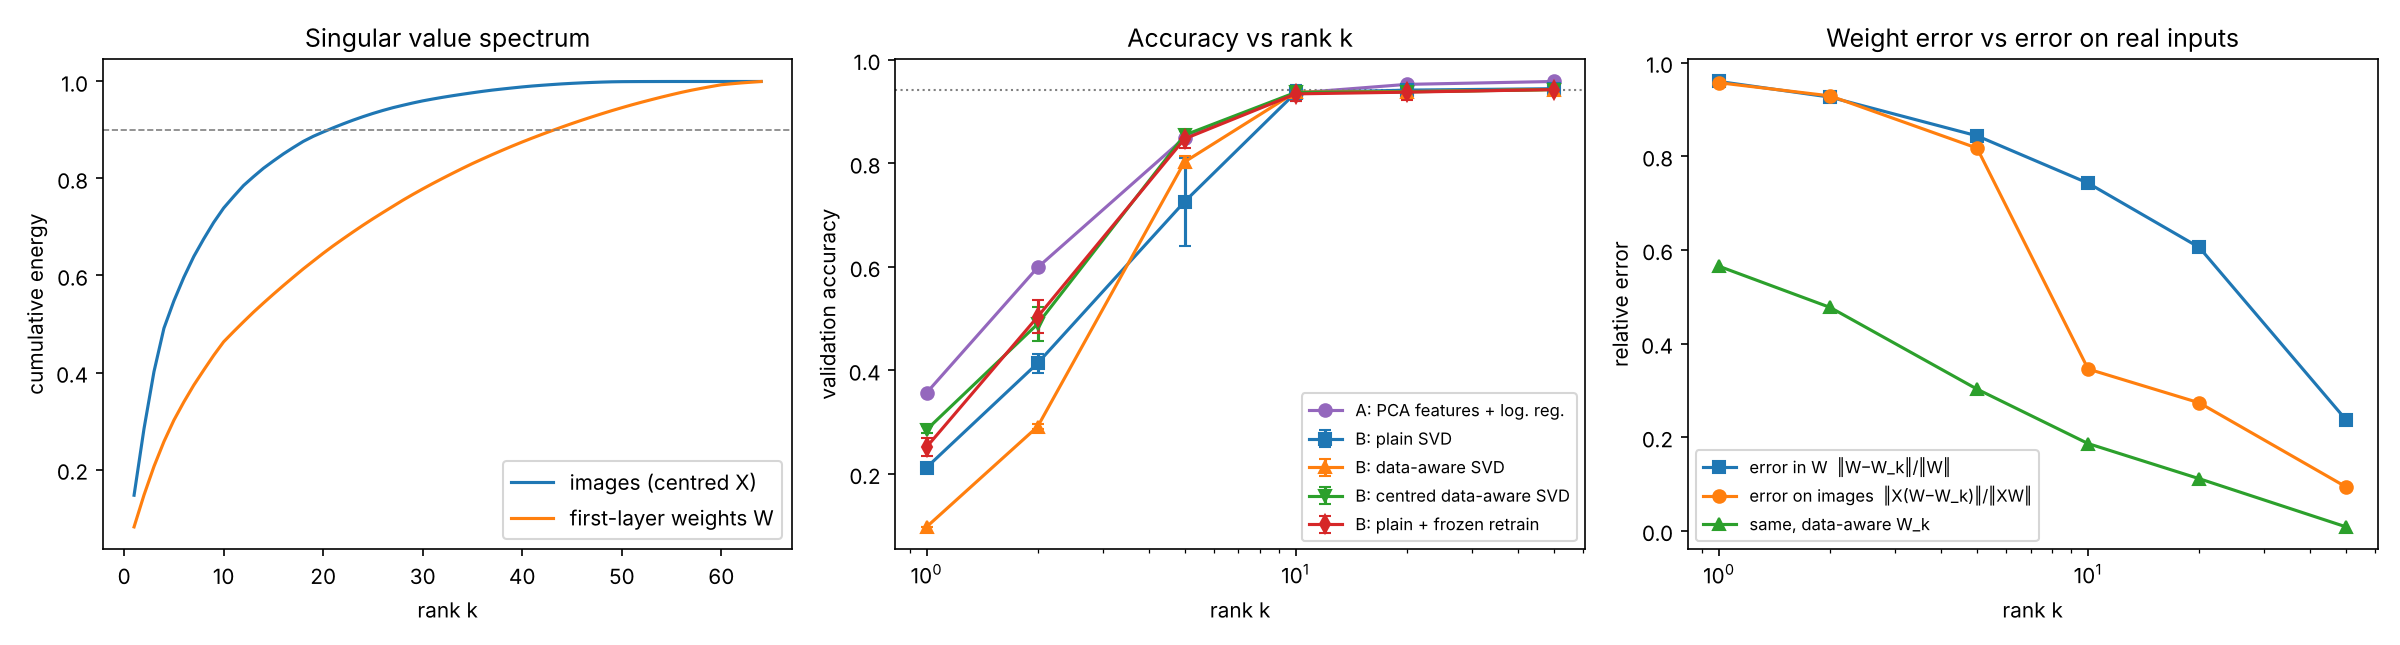

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
ax[0].plot(np.arange(1, len(energy)+1), energy, label="images (centred X)")
ax[0].plot(np.arange(1, len(ew)+1), ew, label="first-layer weights W")
ax[0].axhline(0.9, ls="--", c="gray", lw=0.8)
ax[0].set_xlabel("rank k"); ax[0].set_ylabel("cumulative energy"); ax[0].set_title("Singular value spectrum"); ax[0].legend()
for key, lab, mk in [("plain", "B: plain SVD", "s-"), ("data", "B: data-aware SVD", "^-"), ("datac", "B: centred data-aware SVD", "v-"), ("retrain", "B: plain + frozen retrain", "d-")]:
    mean = [np.mean(R[key][k]) for k in KS]; sd = [np.std(R[key][k]) for k in KS]
    ax[1].errorbar(KS, mean, yerr=sd, fmt=mk, capsize=3, label=lab)
ax[1].plot(KS, [A[k][2] for k in KS], "o-", label="A: PCA features + log. reg.")
ax[1].axhline(np.mean(full_acc), ls=":", c="gray", lw=1)
ax[1].set_xscale("log"); ax[1].set_xlabel("rank k"); ax[1].set_ylabel("validation accuracy"); ax[1].set_title("Accuracy vs rank k"); ax[1].legend(fontsize=8)
ax[2].plot(KS, [np.mean(werr[k]) for k in KS], "s-", label="error in W  ‖W−W_k‖/‖W‖")
ax[2].plot(KS, [np.mean(oerr[k]) for k in KS], "o-", label="error on images  ‖X(W−W_k)‖/‖XW‖")
ax[2].plot(KS, [np.mean(oerr_da[k]) for k in KS], "^-", label="same, data-aware W_k")
ax[2].set_xscale("log"); ax[2].set_xlabel("rank k"); ax[2].set_ylabel("relative error"); ax[2].set_title("Weight error vs error on real inputs"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"results_{DATASET}.png", dpi=150); plt.show()